In [2]:
import numpy as np
from tifffile import imread, imwrite
from pathlib import Path
from matplotlib import pyplot as plt
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
from scipy.stats import rankdata

In [31]:
def process_tif_folder(folder_path):
    folder_path = Path(folder_path)
    for tif_file in folder_path.glob('*.tif'):
        stack = imread(tif_file).astype(np.float32)
        sum_projection = np.sum(stack, axis = 1)
        save_path = folder_path/ f'{tif_file.stem}_SUM.tif'
        imwrite(save_path,sum_projection)
def split_timeseries(folder_path):
    folder_path = Path(folder_path)
    output_folder = Path (folder_path)/"split_slices"
    output_folder.mkdir(exist_ok = True)
    for tif_file in folder_path.glob("*SUM.tif"):
        stack = imread(tif_file).astype(np.float32)
        num_slices = stack.shape[0]
        for i in range(num_slices):
            slice_image = stack[i,:,:]
            save_path = output_folder/f"{tif_file.stem}_slice_{i}.tif"
            imwrite(save_path,slice_image)
    for npy_file in folder_path.glob("*.npy"):
        data = np.load(npy_file)
        num_slice = data.shape[0]
        for i in range(num_slice):
            data_slice = data[i,:,:]
            save_path = output_folder/f"{npy_file.stem}_slice_{i}.npy"
            np.save(save_path,data_slice)
def calculate_features(folder_path, border=20, win_k=3):
    folder_path = Path(folder_path)
    r = win_k // 2
    assert border >= r, "border must be >= win_k // 2"

    files = sorted(folder_path.glob("*SUM_slice_*.tif"))
    print(f"Found {len(files)} tif files")

    feature_names = (['intensity', 'Ix', 'Iy', 'Ixx', 'Iyy', 'Ixy']
                     + [f'win_dy{dy}_dx{dx}' for dy in range(-r, r + 1) for dx in range(-r, r + 1)])
    X_list, y_list, meta_list, image_names = [], [], [], []

    for tif_file in files:
        label_file = folder_path / (tif_file.stem.replace("_SUM", "") + ".npy")
        if not label_file.exists():
            print(f"SKIPPING {tif_file.name}: no label file {label_file.name}")
            continue

        img = imread(tif_file).astype(np.float32)
        labels = np.load(label_file)
        if img.shape != labels.shape:
            raise ValueError(f"{tif_file.name}: image {img.shape} vs labels {labels.shape}")

        H, W = img.shape
        if H <= 2 * border or W <= 2 * border:
            raise ValueError(f"{tif_file.name}: border={border} too big for {img.shape}")

        # ---- 1) normalize + derivative features on the FULL image ----
        norm_img = (img - np.mean(img)) / (np.std(img) + 1e-8)
        Ix  = np.gradient(norm_img, axis=1)
        Iy  = np.gradient(norm_img, axis=0)
        Ixx = np.gradient(Ix, axis=1)
        Iyy = np.gradient(Iy, axis=0)
        Ixy = np.gradient(Ix, axis=0)

        # ---- 2) local neighborhood rank on the FULL image ----
        padded = np.pad(norm_img, r, mode='reflect')
        win = sliding_window_view(padded, (win_k, win_k)).reshape(H * W, win_k * win_k)
        win_rank = rankdata(win, axis=1, method='average')      # 1..k*k within each window
        win_rank = (win_rank - 1) / (win_k * win_k - 1)         # scale to [0, 1]
        win_rank = win_rank.reshape(H, W, win_k * win_k).astype(np.float32)

        # ---- 3) CROP the edge pixels (features and labels together) ----
        sl = (slice(border, H - border), slice(border, W - border))
        base = np.stack([norm_img[sl], Ix[sl], Iy[sl], Ixx[sl], Iyy[sl], Ixy[sl]], axis=-1)
        feats = np.concatenate([base, win_rank[sl]], axis=-1)   # (h, w, 6 + k*k)
        lab = labels[sl]
        h, w = lab.shape

        # ---- 4) build the data matrix rows ----
        rr, cc = np.indices((h, w))
        image_id = len(image_names)
        image_names.append(tif_file.stem)

        X_list.append(feats.reshape(-1, feats.shape[-1]).astype(np.float32))
        y_list.append(lab.ravel())
        meta_list.append(pd.DataFrame({
            'image_id': np.full(h * w, image_id, dtype=np.int32),
            'row': (rr.ravel() + border).astype(np.int32),      # coords in the ORIGINAL image
            'col': (cc.ravel() + border).astype(np.int32),
        }))

    X = np.vstack(X_list)
    y = np.concatenate(y_list)
    meta = pd.concat(meta_list, ignore_index=True)
    assert len(X) == len(y) == len(meta)
    return X, y, meta, feature_names, image_names
    
    


In [ ]:
#Making the data matrix
X, y, meta, feature_names, image_names = calculate_features(
    '/Users/gs3133/Desktop/ML project/split_slices', border=20, win_k=3)

print(X.shape, y.shape, meta.shape, len(feature_names))


Found 217 tif files
(10124352, 15) (10124352,) (10124352, 3) 15


In [33]:
df = pd.DataFrame(X, columns=feature_names)
df['label'] = y
df['image_id'] = meta['image_id'].to_numpy()
df['row'] = meta['row'].to_numpy()
df['col'] = meta['col'].to_numpy()
df['file'] = df['image_id'].map(dict(enumerate(image_names)))

print(df.shape)
df.head()

(10124352, 20)


,intensity,Ix,Iy,Ixx,Iyy,Ixy,win_dy-1_dx-1,win_dy-1_dx0,win_dy-1_dx1,win_dy0_dx-1,win_dy0_dx0,win_dy0_dx1,win_dy1_dx-1,win_dy1_dx0,win_dy1_dx1,label,image_id,row,col,file
0,-0.286181,-0.189780,0.133549,-0.105434,0.214382,-0.014058,0.500,0.0000,0.3125,1.0000,0.3125,0.125,0.875,0.750,0.625,0,0,20,20,20250522-E3_SUM_slice_0
1,-0.384586,0.056231,0.042173,0.196809,-0.231954,0.210867,0.125,0.4375,0.0000,0.4375,0.2500,0.875,0.750,0.625,1.000,0,0,20,21,20250522-E3_SUM_slice_0
2,-0.173718,0.203838,0.555283,0.312786,-0.038659,0.277642,0.375,0.0000,0.1250,0.2500,0.6250,0.750,0.500,0.875,1.000,0,0,20,22,20250522-E3_SUM_slice_0
3,0.023091,0.681804,0.597457,0.277642,-0.045688,-0.323330,0.000,0.1250,1.0000,0.2500,0.3750,0.875,0.500,0.625,0.750,1,0,20,23,20250522-E3_SUM_slice_0
4,1.189889,0.759121,-0.091376,-0.797781,0.340902,-0.527168,0.000,0.7500,1.0000,0.1250,0.6250,0.875,0.250,0.500,0.375,1,0,20,24,20250522-E3_SUM_slice_0


             n_images  n_pixels  pos_frac
fish                                     
20250522-E3        31   1446336  0.141433
20250626-C1        31   1446336  0.118653
20250626-C2        31   1446336  0.131709
20250724-C1        31   1446336  0.137106
20250807-C1        31   1446336  0.140557
20250821-C1        31   1446336  0.161751
20250821-C2        31   1446336  0.154306


/var/folders/lf/kypt8cyx0k125ftxjhwzgnxmdtbtv9/T/ipykernel_86259/2868621524.py:25: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), 50_000), random_state=0)))


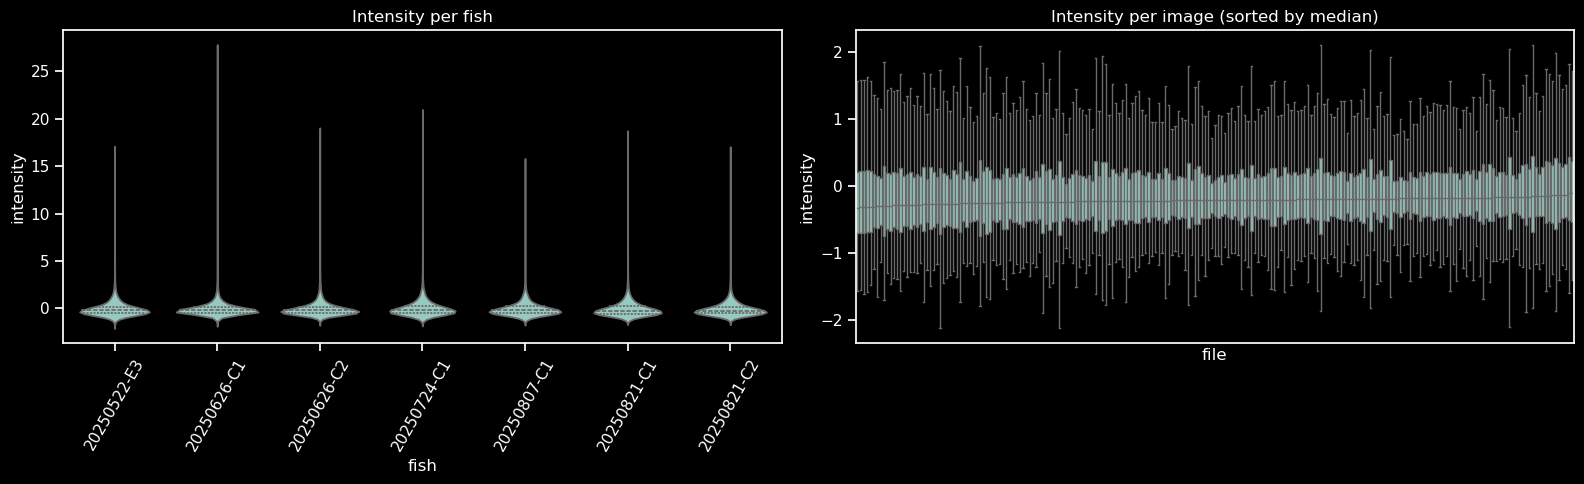

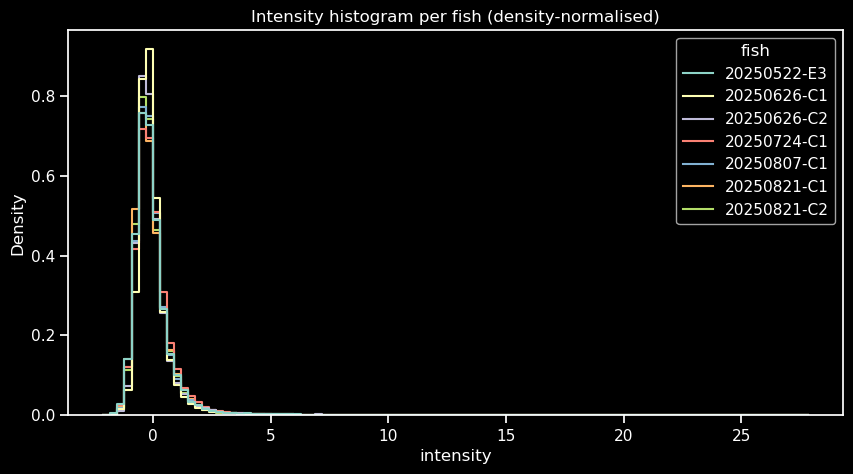

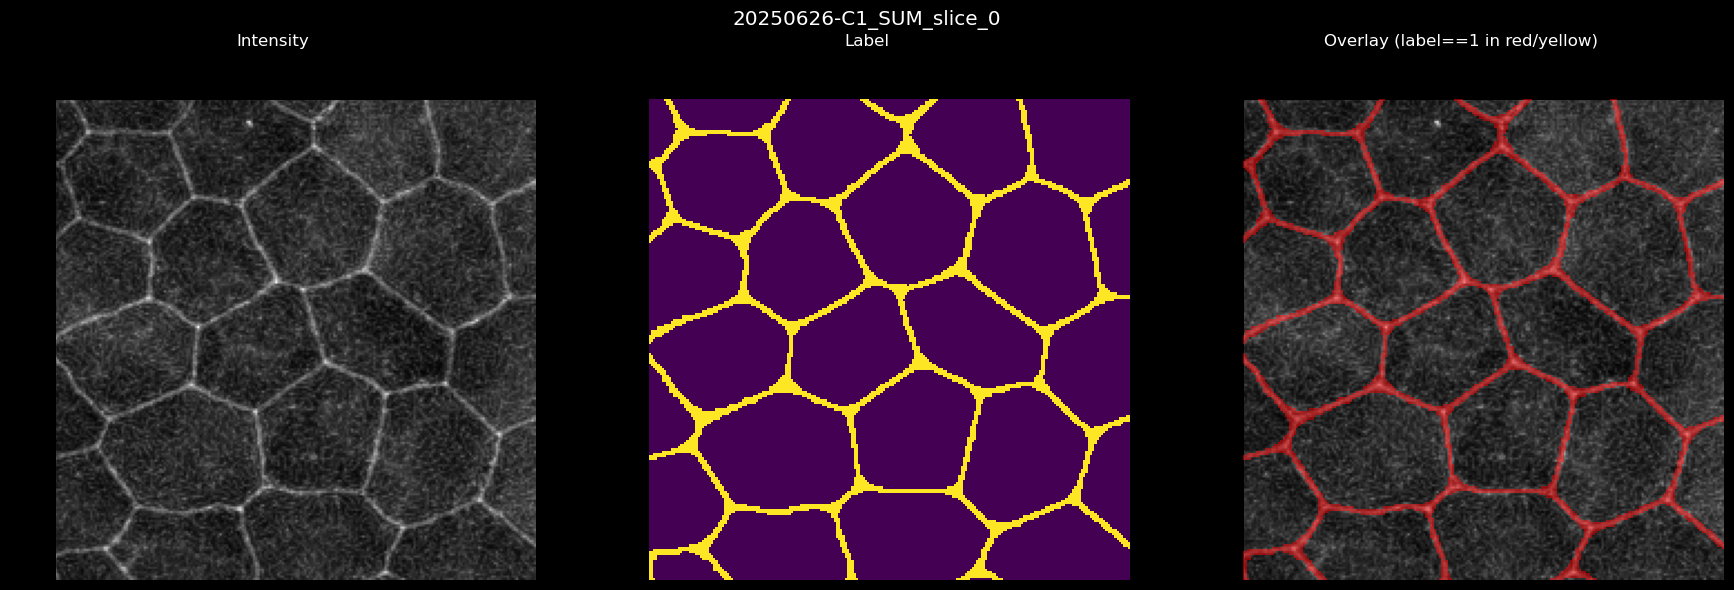

label
0    8698965
1    1425387
Name: count, dtype: int64 
 label
0    0.8592
1    0.1408
Name: count, dtype: float64


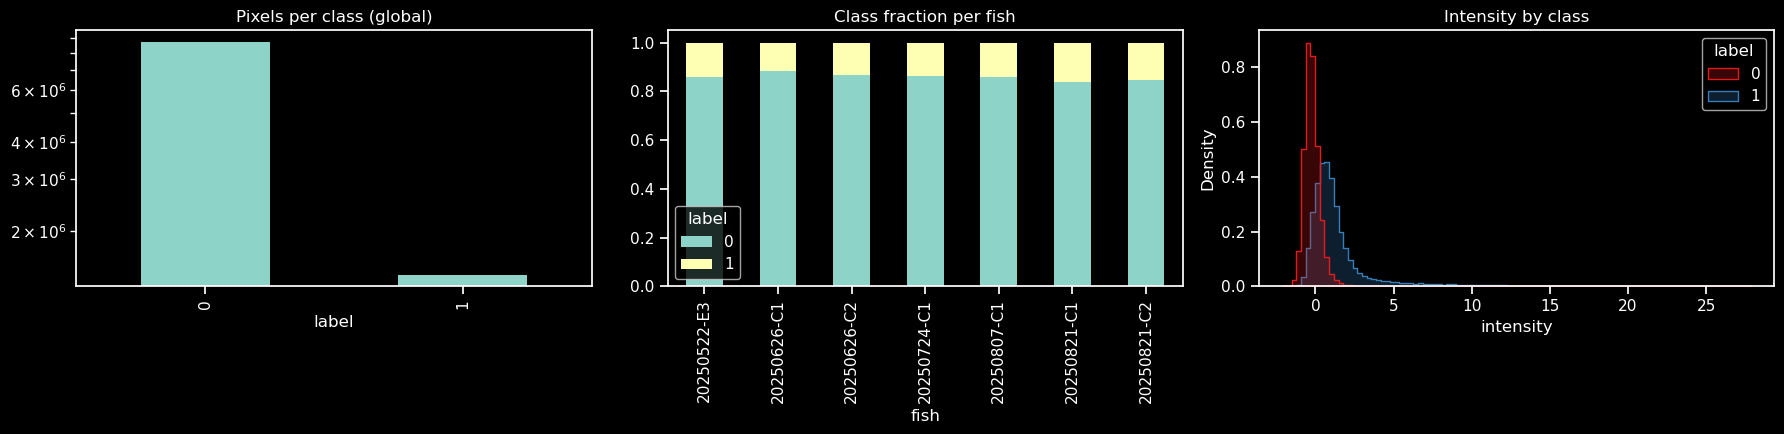

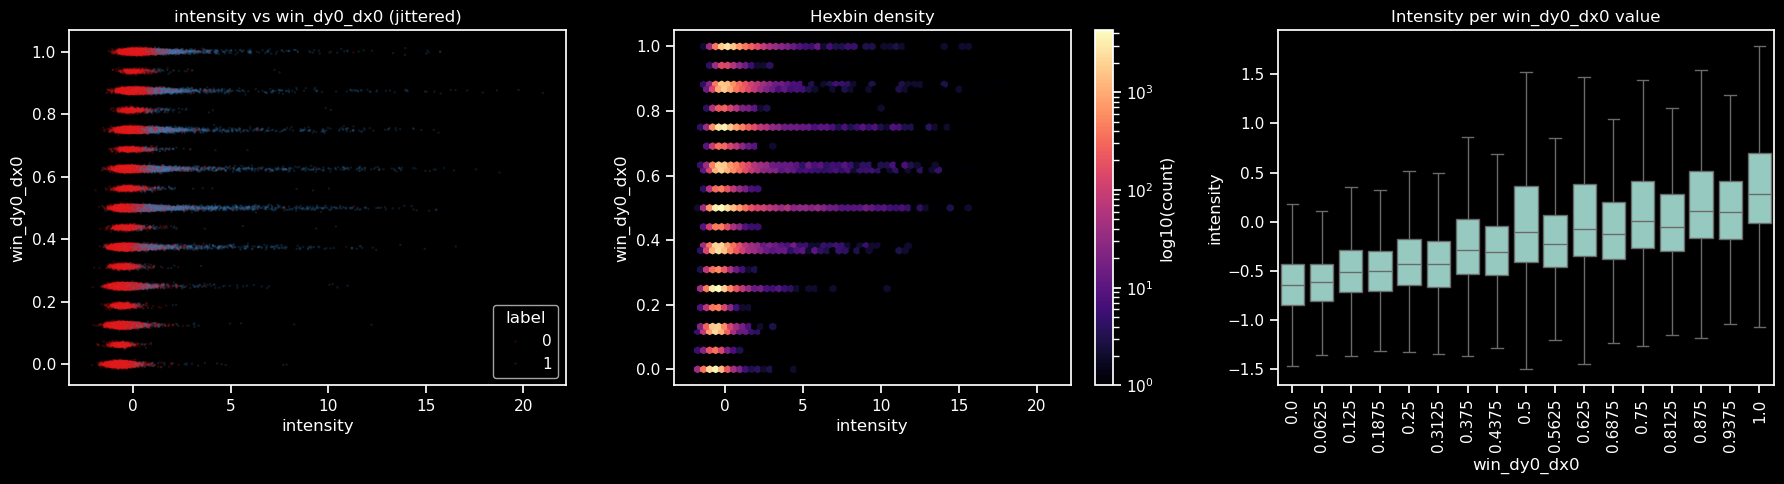

Pearson : 0.309164382613459
Spearman: 0.5304167689579898


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("dark_background")   # black figure/axes bg, white text, ticks, spines
sns.set_context("notebook")        # keep this; don't call sns.set_theme() afterwards
                                   # (it would overwrite the dark style)
rng = np.random.default_rng(0)

# ---- Setup ---------------------------------------------------------------
# fish id = first token of the file stem, e.g. '20250522-E3_SUM_slice_0' -> '20250522-E3'
df["fish"] = df["file"].str.split("_").str[0].astype("category")
df["file"] = df["file"].astype("category")
df["label"] = df["label"].astype("int8")

print(df.groupby("fish", observed=True).agg(
    n_images=("image_id", "nunique"),
    n_pixels=("intensity", "size"),
    pos_frac=("label", "mean"),
))

# Subsample for plotting (stratified by fish so every fish is represented)
sample = (df.groupby("fish", observed=True, group_keys=False)
            .apply(lambda g: g.sample(min(len(g), 50_000), random_state=0)))

# ---- 1. Intensity distribution across images / fish ----------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# per fish
sns.violinplot(data=sample, x="fish", y="intensity", cut=0, inner="quartile", ax=axes[0])
axes[0].set_title("Intensity per fish")
axes[0].tick_params(axis="x", rotation=60)

# per image (file) – boxplot is lighter than violins when there are many images
order = sample.groupby("file", observed=True)["intensity"].median().sort_values().index
sns.boxplot(data=sample, x="file", y="intensity", order=order,
            showfliers=False, ax=axes[1])
axes[1].set_title("Intensity per image (sorted by median)")
axes[1].set_xticks([])  # too many labels; remove
plt.tight_layout(); plt.show()

# overlaid KDE/hist per fish – good for spotting batch/brightness shifts
plt.figure(figsize=(10, 5))
sns.histplot(data=sample, x="intensity", hue="fish", element="step",
             stat="density", common_norm=False, bins=100, fill=False)
plt.title("Intensity histogram per fish (density-normalised)")
plt.show()

# ---- 2. Example image with label overlay ---------------------------------
def to_image(d, value_col):
    """Rebuild a 2D array from row/col coords. Missing pixels -> NaN."""
    H, W = d["row"].max() + 1, d["col"].max() + 1
    out = np.full((H, W), np.nan, dtype="float32")
    out[d["row"].values, d["col"].values] = d[value_col].values
    return out

example_file = df["file"].cat.categories[31]        # or pick any file name
d = df[df["file"] == example_file]
img = to_image(d, "intensity")
lab = to_image(d, "label")

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
axes[0].imshow(img, cmap="gray");                         axes[0].set_title("Intensity")
axes[1].imshow(lab, cmap="viridis", interpolation="nearest"); axes[1].set_title("Label")
axes[2].imshow(img, cmap="gray")
overlay = np.ma.masked_where(~(lab == 1), lab)            # show only positive class
axes[2].imshow(overlay, cmap="autumn", alpha=0.5, interpolation="nearest")
axes[2].set_title("Overlay (label==1 in red/yellow)")
for a in axes: a.axis("off")
plt.suptitle(example_file); plt.tight_layout(); plt.show()

# ---- 3. Class distribution -----------------------------------------------
counts = df["label"].value_counts().sort_index()
print(counts, "\n", (counts / counts.sum()).round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
counts.plot.bar(ax=axes[0]); axes[0].set_title("Pixels per class (global)")
axes[0].set_yscale("log")

# class balance per fish
bal = pd.crosstab(df["fish"], df["label"], normalize="index")
bal.plot.bar(stacked=True, ax=axes[1]); axes[1].set_title("Class fraction per fish")

# intensity by class
sns.histplot(data=sample, x="intensity", hue="label", element="step",
             stat="density", common_norm=False, bins=100, ax=axes[2], palette="Set1")
axes[2].set_title("Intensity by class")
plt.tight_layout(); plt.show()

# ---- 4. intensity vs win_dy0_dx0 -----------------------------------------
s = sample.sample(min(len(sample), 100_000), random_state=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# scatter coloured by class (alpha + jitter because win_* looks discretised)
jit = rng.normal(0, 0.004, len(s))
sns.scatterplot(x=s["intensity"], y=s["win_dy0_dx0"] + jit, hue=s["label"],
                s=3, alpha=0.2, palette="Set1", ax=axes[0], linewidth=0)
axes[0].set_title("intensity vs win_dy0_dx0 (jittered)")

# density view – handles overplotting
hb = axes[1].hexbin(s["intensity"], s["win_dy0_dx0"], gridsize=60, bins="log", cmap="magma")
plt.colorbar(hb, ax=axes[1], label="log10(count)")
axes[1].set_title("Hexbin density")
axes[1].set_xlabel("intensity"); axes[1].set_ylabel("win_dy0_dx0")

# since win_dy0_dx0 takes few distinct values, a boxplot per value is often clearer
sns.boxplot(data=s, x="win_dy0_dx0", y="intensity", showfliers=False, ax=axes[2])
axes[2].set_title("Intensity per win_dy0_dx0 value")
axes[2].tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

print("Pearson :", s[["intensity", "win_dy0_dx0"]].corr().iloc[0, 1])
print("Spearman:", s[["intensity", "win_dy0_dx0"]].corr(method="spearman").iloc[0, 1])

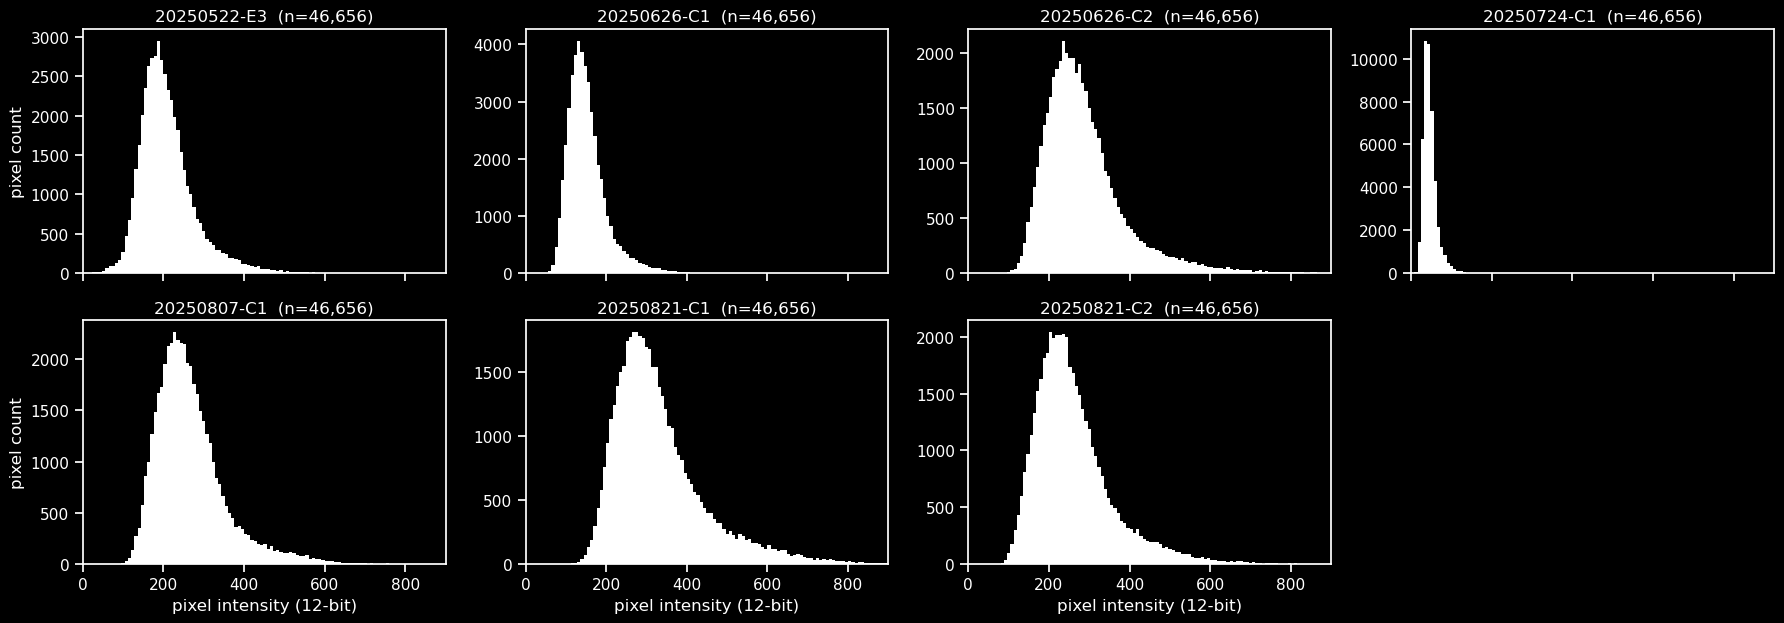

In [35]:
# Zoom x to the data: up to the 99.9th percentile across the first-slice pixels
xmax = int(np.ceil(first["intensity"].quantile(0.999) / 50) * 50)   # round up to nearest 50
bin_w = 8                                                            # intensity units per bin
edges = np.arange(0, xmax + bin_w, bin_w)

fish_list = sorted(first["fish"].astype(str).unique())
ncols = 4
nrows = int(np.ceil(len(fish_list) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.2 * nrows),
                         sharex=True, sharey=False, squeeze=False)

for ax, f in zip(axes.ravel(), fish_list):
    x = first.loc[first["fish"].astype(str) == f, "intensity"].values
    counts, _ = np.histogram(x, bins=edges)
    ax.bar(edges[:-1], counts, width=bin_w, align="edge", color="white", edgecolor="none")
    ax.set_title(f"{f}  (n={len(x):,})")
    ax.set_xlim(0, xmax)

for ax in axes.ravel()[len(fish_list):]:
    ax.axis("off")

for ax in axes[:, 0]: ax.set_ylabel("pixel count")
for ax in axes[-1, :]: ax.set_xlabel("pixel intensity (12-bit)")

plt.tight_layout(); plt.show()

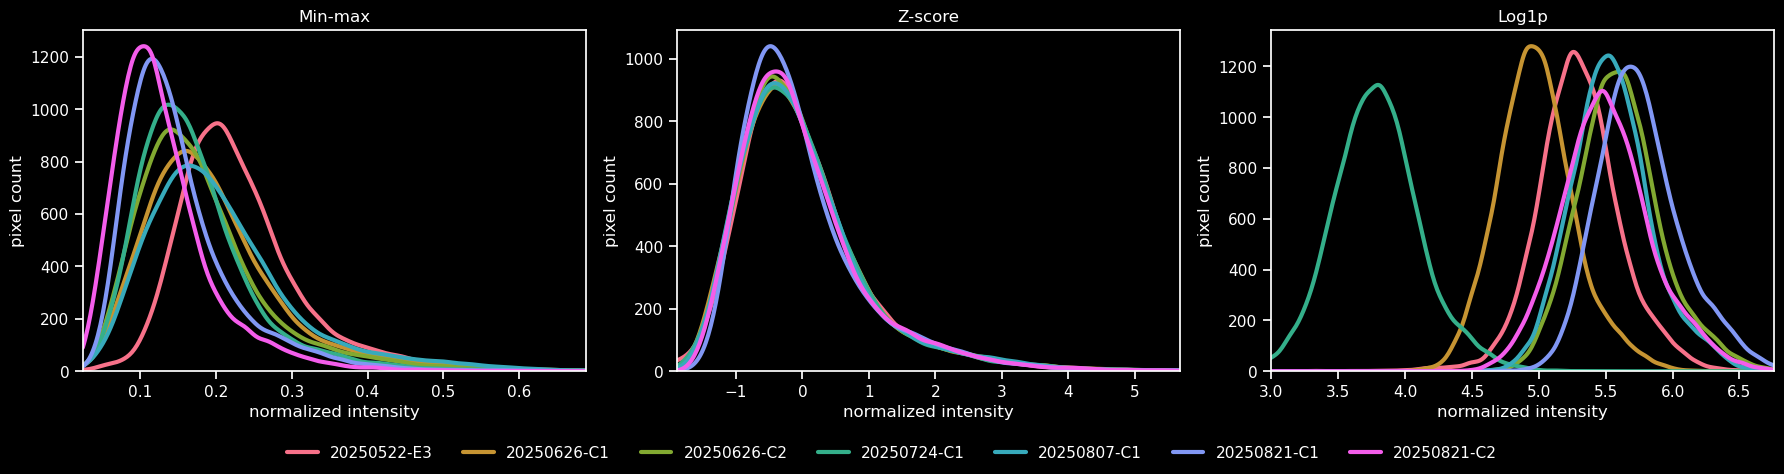

In [48]:
norms = {
    "Min-max": lambda x: (x - x.min()) / (x.max() - x.min()),
    "Z-score": lambda x: (x - x.mean()) / x.std(),
    "Log1p":   lambda x: np.log1p(x),
}

first = first.reset_index(drop=True)
inten = first["intensity"].values.astype("float64")
out = {name: np.empty_like(inten) for name in norms}

for f, idx in first.groupby("file", observed=True).indices.items():
    x = inten[idx]
    for name, fn in norms.items():
        out[name][idx] = fn(x)

fish_arr = first["fish"].astype(str).values
fish_list = sorted(np.unique(fish_arr))
colors = dict(zip(fish_list, sns.color_palette("husl", len(fish_list))))

from scipy.stats import gaussian_kde

lw = 3            # line thickness
bw = None         # KDE bandwidth: None = automatic; try 0.1-0.3 for smoother/stiffer curves

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (name, vals) in zip(axes, out.items()):
    lo, hi = np.percentile(vals, [0.1, 99.9])
    grid = np.linspace(lo, hi, 400)
    bin_w = (hi - lo) / 200                       # same scale as the earlier 200-bin histograms
    for f in fish_list:
        x = vals[fish_arr == f]
        kde = gaussian_kde(x, bw_method=bw)
        y = kde(grid) * len(x) * bin_w            # density -> pixel count per bin
        ax.plot(grid, y, color=colors[f], lw=lw, label=f, solid_capstyle="round")
    ax.set_title(name)
    ax.set_xlim(lo, hi)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("normalized intensity")
    ax.set_ylabel("pixel count")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(fish_list), frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

             mean  std
fish                  
20250522-E3  -0.0  1.0
20250626-C1   0.0  1.0
20250626-C2  -0.0  1.0
20250724-C1   0.0  1.0
20250807-C1   0.0  1.0
20250821-C1  -0.0  1.0
20250821-C2  -0.0  1.0


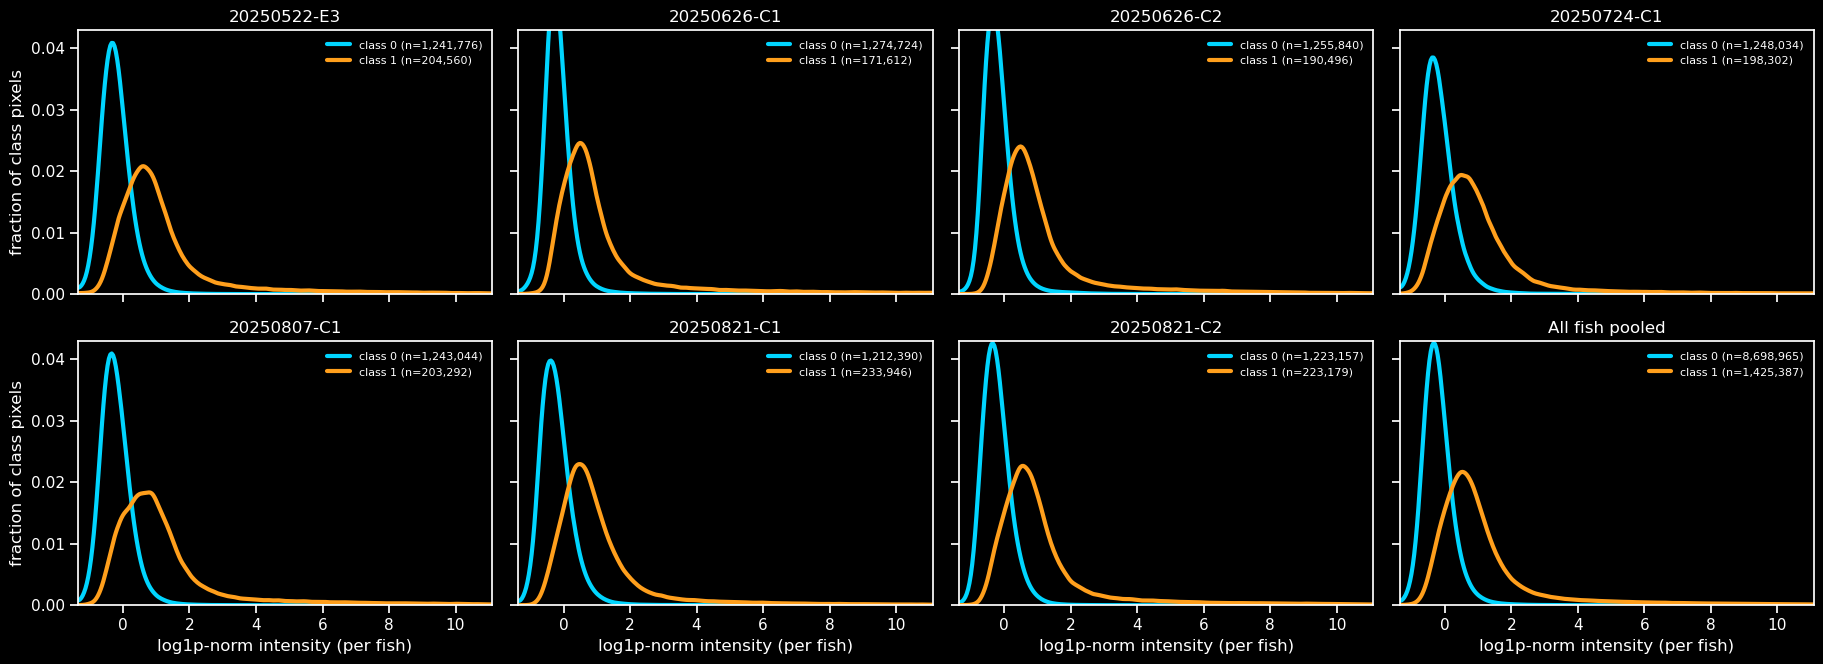

                   n_pixels  mean  median   std
fish        label                              
20250522-E3 0       1241776 -0.22   -0.26  0.46
            1        204560  1.31    0.80  1.95
20250626-C1 0       1274724 -0.18   -0.23  0.42
            1        171612  1.34    0.68  2.26
20250626-C2 0       1255840 -0.20   -0.26  0.46
            1        190496  1.32    0.72  2.05
20250724-C1 0       1248034 -0.19   -0.26  0.55
            1        198302  1.19    0.75  1.94
20250807-C1 0       1243044 -0.22   -0.27  0.46
            1        203292  1.33    0.84  1.95
20250821-C1 0       1212390 -0.22   -0.29  0.48
            1        233946  1.17    0.71  1.83
20250821-C2 0       1223157 -0.23   -0.28  0.43
            1        223179  1.25    0.75  1.90


In [51]:
from scipy.ndimage import gaussian_filter1d

# ---- Per-fish z-score (one mean/std per fish, all its images pooled) ------
g = df.groupby("fish", observed=True)["intensity"]
df["intensity_z"] = ((df["intensity"] - g.transform("mean")) / g.transform("std")).astype("float32")

# df["intensity_z"] = (
#     (df["intensity"] - g.transform("min")) /
#     (g.transform("max") - g.transform("min"))
# ).astype("float32")
# df["intensity_z"] = np.log1p(df["intensity"]).astype("float32")

# sanity check: every fish should have mean ~0, std ~1
print(df.groupby("fish", observed=True)["intensity_z"].agg(["mean", "std"]).round(4))

# ---- Per-class, per-fish distributions ------------------------------------
DENSITY = True     # True: each class area = 1; False: raw pixel counts
SIGMA   = 2        # smoothing in bins
LW      = 3
class_colors = {0: "#00d5ff", 1: "#ff9f1c"}

z   = df["intensity_z"].values
lab = df["label"].values
fsh = df["fish"].astype(str).values
fish_list = sorted(np.unique(fsh))

lo, hi = np.percentile(rng.choice(z, 1_000_000), [0.1, 99.9])
edges = np.linspace(lo, hi, 301)
centers = 0.5 * (edges[:-1] + edges[1:])

def curve(x):
    counts, _ = np.histogram(x, bins=edges)
    y = gaussian_filter1d(counts.astype(float), SIGMA)
    return y / y.sum() if DENSITY else y

panels = fish_list + ["All fish pooled"]
ncols = 4
nrows = int(np.ceil(len(panels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.4 * nrows),
                         sharex=True, sharey=DENSITY, squeeze=False)

for ax, f in zip(axes.ravel(), panels):
    m_f = np.ones(len(z), bool) if f == "All fish pooled" else (fsh == f)
    for c in (0, 1):
        x = z[m_f & (lab == c)]
        ax.plot(centers, curve(x), color=class_colors[c], lw=LW, solid_capstyle="round",
                label=f"class {c} (n={len(x):,})")
    ax.set_title(f)
    ax.set_xlim(lo, hi)
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False, fontsize=8, loc="upper right")

for ax in axes.ravel()[len(panels):]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("fraction of class pixels" if DENSITY else "pixel count")
for ax in axes[-1, :]:
    ax.set_xlabel("log1p-norm intensity (per fish)")

plt.tight_layout(); plt.show()

# ---- Class separation in z units, per fish --------------------------------
summ = (df.assign(fish=df["fish"].astype(str))
          .groupby(["fish", "label"])["intensity_z"]
          .agg(n_pixels="size", mean="mean", median="median", std="std"))
print(summ.round(2))

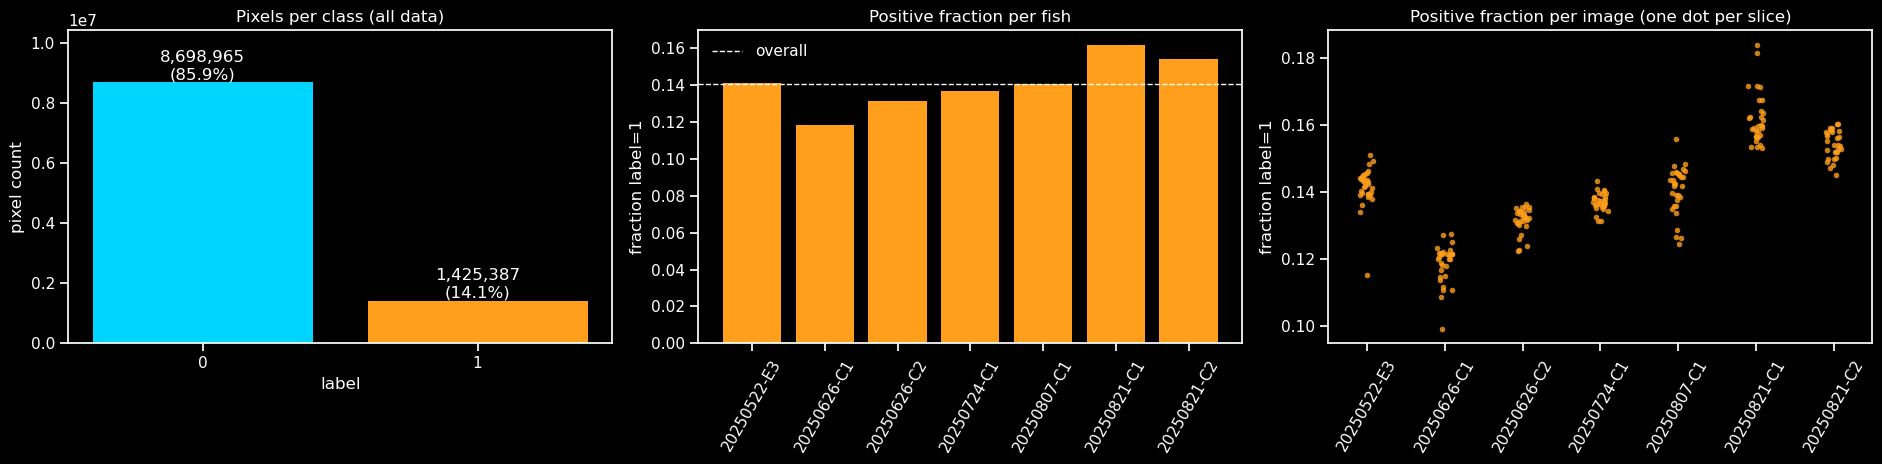

/var/folders/lf/kypt8cyx0k125ftxjhwzgnxmdtbtv9/T/ipykernel_86259/3657159784.py:41: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), 30_000), random_state=0)))


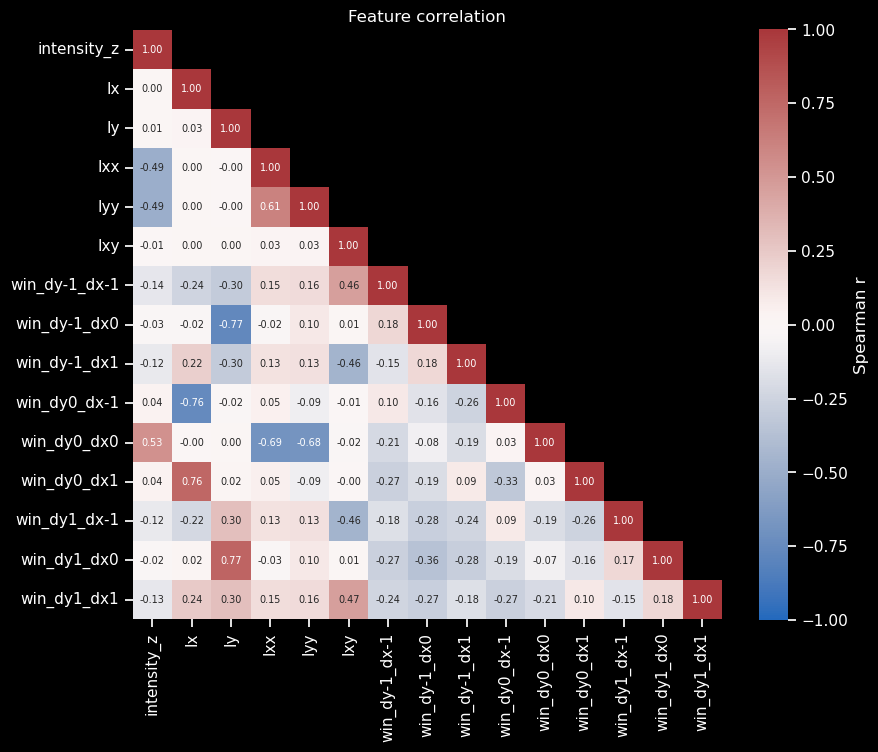

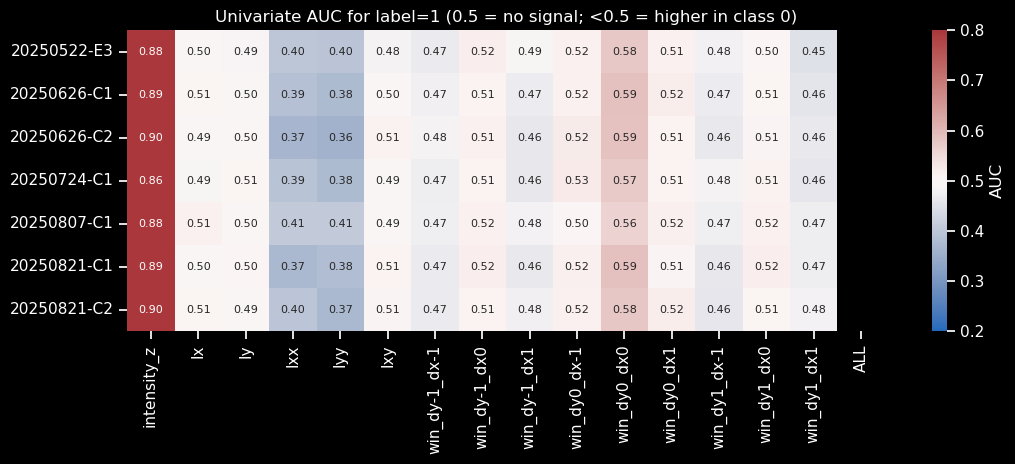

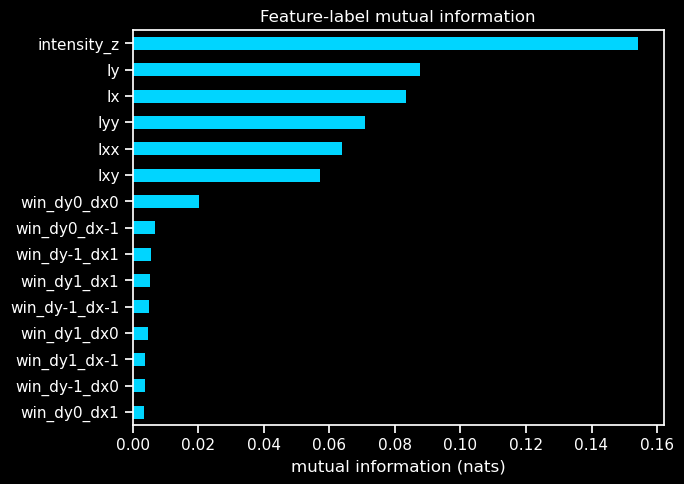

In [52]:
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif

feat_cols = ["intensity_z", "Ix", "Iy", "Ixx", "Iyy", "Ixy"] + \
            [c for c in df.columns if c.startswith("win_")]
# row/col/image_id are excluded on purpose: position and ID aren't real features and would leak

df["fish_s"] = df["fish"].astype(str)
df["slice"]  = df["file"].astype(str).str.extract(r"slice_(\d+)").astype(int)

# =========================== 1. CLASS IMBALANCE ===========================
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))

# global counts
cnt = df["label"].value_counts().sort_index()
axes[0].bar(cnt.index.astype(str), cnt.values, color=["#00d5ff", "#ff9f1c"])
for i, v in enumerate(cnt.values):
    axes[0].text(i, v, f"{v:,}\n({v/cnt.sum():.1%})", ha="center", va="bottom")
axes[0].set_title("Pixels per class (all data)")
axes[0].set_ylabel("pixel count"); axes[0].set_xlabel("label")
axes[0].set_ylim(0, cnt.max() * 1.2)

# positive fraction per fish
pf = df.groupby("fish_s")["label"].mean()
axes[1].bar(pf.index, pf.values, color="#ff9f1c")
axes[1].axhline(df["label"].mean(), color="white", ls="--", lw=1, label="overall")
axes[1].set_title("Positive fraction per fish"); axes[1].set_ylabel("fraction label=1")
axes[1].tick_params(axis="x", rotation=60); axes[1].legend(frameon=False)

# positive fraction per image (each dot = one slice), shows within-fish spread
pi = df.groupby(["fish_s", "slice"])["label"].mean().reset_index()
sns.stripplot(data=pi, x="fish_s", y="label", color="#ff9f1c", size=4, alpha=0.8, ax=axes[2])
axes[2].set_title("Positive fraction per image (one dot per slice)")
axes[2].set_ylabel("fraction label=1"); axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

# =========================== 2. FEATURE DEPENDENCE ========================
# Stratified-by-fish subsample (neighbouring pixels are highly correlated, so 10M rows adds little)
samp = (df.groupby("fish_s", group_keys=False)
          .apply(lambda g: g.sample(min(len(g), 30_000), random_state=0)))
X, y = samp[feat_cols], samp["label"].values

# --- 2a. feature vs feature (redundancy / collinearity) ---
corr = X.corr(method="spearman")
mask = np.triu(np.ones_like(corr, bool), k=1)
plt.figure(figsize=(9, 7.5))
sns.heatmap(corr, mask=mask, cmap="vlag", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True,
            cbar_kws={"label": "Spearman r"})
plt.title("Feature correlation"); plt.tight_layout(); plt.show()

# --- 2b. feature vs label: univariate AUC, pooled and per fish ---
def auc_table(d):
    return {c: roc_auc_score(d["label"], d[c]) for c in feat_cols}

auc = pd.DataFrame({f: auc_table(g) for f, g in samp.groupby("fish_s")}).T
auc["ALL"] = pd.Series(auc_table(samp))

plt.figure(figsize=(11, 4.8))
sns.heatmap(auc, cmap="vlag", center=0.5, vmin=0.2, vmax=0.8,
            annot=True, fmt=".2f", annot_kws={"size": 8}, cbar_kws={"label": "AUC"})
plt.title("Univariate AUC for label=1 (0.5 = no signal; <0.5 = higher in class 0)")
plt.tight_layout(); plt.show()

# --- 2c. feature vs label: mutual information (catches non-monotonic dependence) ---
sub = samp.sample(min(len(samp), 100_000), random_state=0)
mi = pd.Series(mutual_info_classif(sub[feat_cols], sub["label"], random_state=0),
               index=feat_cols).sort_values()
plt.figure(figsize=(7, 5))
mi.plot.barh(color="#00d5ff"); plt.xlabel("mutual information (nats)")
plt.title("Feature-label mutual information"); plt.tight_layout(); plt.show()

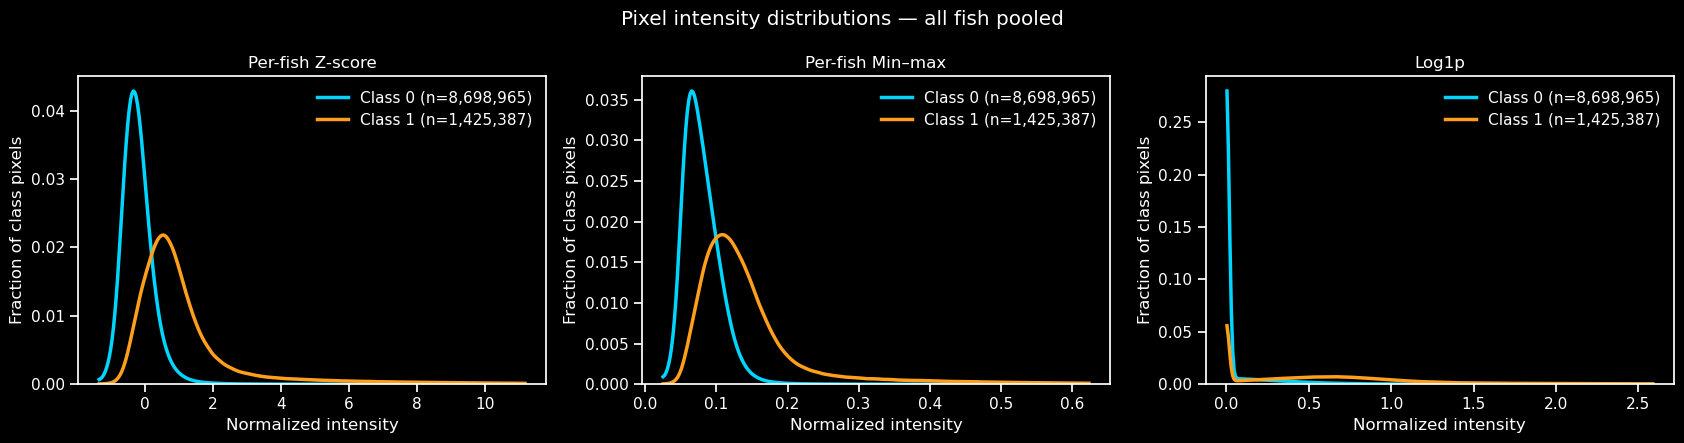

In [47]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# ---- Normalization methods -----------------------------------------
g = df.groupby("fish", observed=True)["intensity"]

# Per-fish z-score
mean = g.transform("mean")
std = g.transform("std")
df["intensity_zscore"] = (
    (df["intensity"] - mean) / std.replace(0, np.nan)
).fillna(0).astype("float32")

# Per-fish min-max
minimum = g.transform("min")
maximum = g.transform("max")
denom = maximum - minimum
df["intensity_minmax"] = (
    (df["intensity"] - minimum) / denom.replace(0, np.nan)
).fillna(0).astype("float32")

# Log1p (not per-fish normalized)
df["intensity_log1p"] = np.log1p(
    df["intensity"].clip(lower=0)
).astype("float32")


# ---- Plot settings --------------------------------------------------
methods = [
    ("intensity_zscore", "Per-fish Z-score"),
    ("intensity_minmax", "Per-fish Min–max"),
    ("intensity_log1p", "Log1p"),
]

class_colors = {0: "#00d5ff", 1: "#ff9f1c"}
SIGMA = 2
N_BINS = 300
DENSITY = True

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, (col, title) in zip(axes, methods):
    z = df[col].to_numpy()
    labels = df["label"].to_numpy()

    lo, hi = np.nanpercentile(z, [0.1, 99.9])
    edges = np.linspace(lo, hi, N_BINS + 1)
    centers = (edges[:-1] + edges[1:]) / 2

    for c in (0, 1):
        x = z[(labels == c) & np.isfinite(z)]

        counts, _ = np.histogram(x, bins=edges)
        y = gaussian_filter1d(counts.astype(float), SIGMA)

        if DENSITY and y.sum() > 0:
            y /= y.sum()

        ax.plot(
            centers, y,
            color=class_colors[c],
            lw=2.5,
            label=f"Class {c} (n={len(x):,})"
        )

    ax.set_title(title)
    ax.set_xlabel("Normalized intensity")
    ax.set_ylabel(
        "Fraction of class pixels" if DENSITY else "Pixel count"
    )
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False)

plt.suptitle("Pixel intensity distributions — all fish pooled")
plt.tight_layout()
plt.show()


/var/folders/lf/kypt8cyx0k125ftxjhwzgnxmdtbtv9/T/ipykernel_86259/1172540446.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), 50_000), random_state=0)))


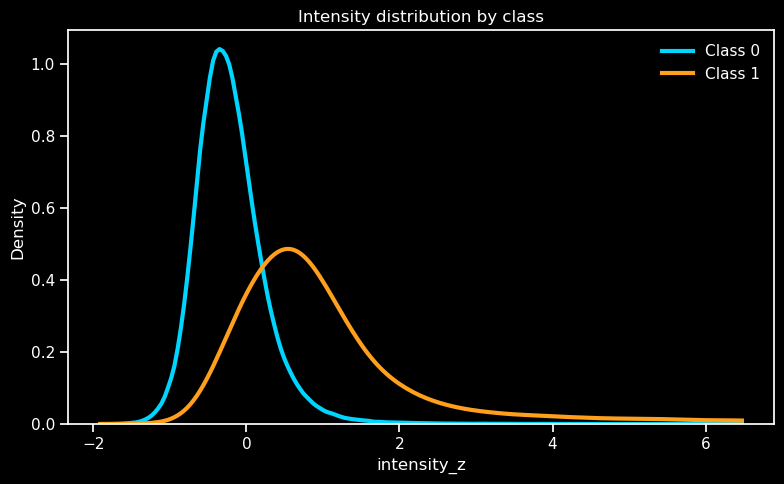

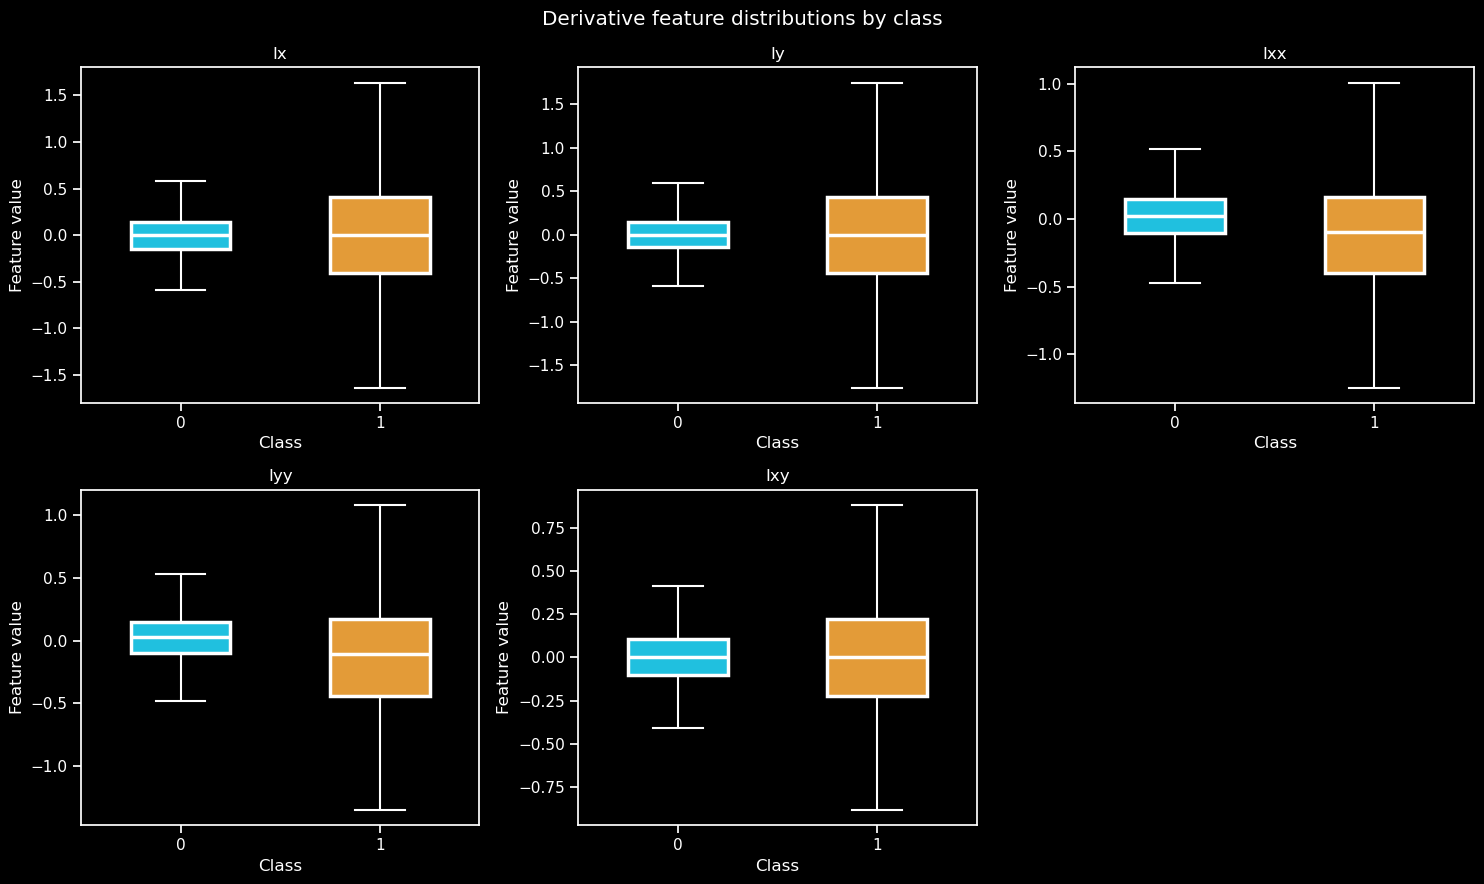

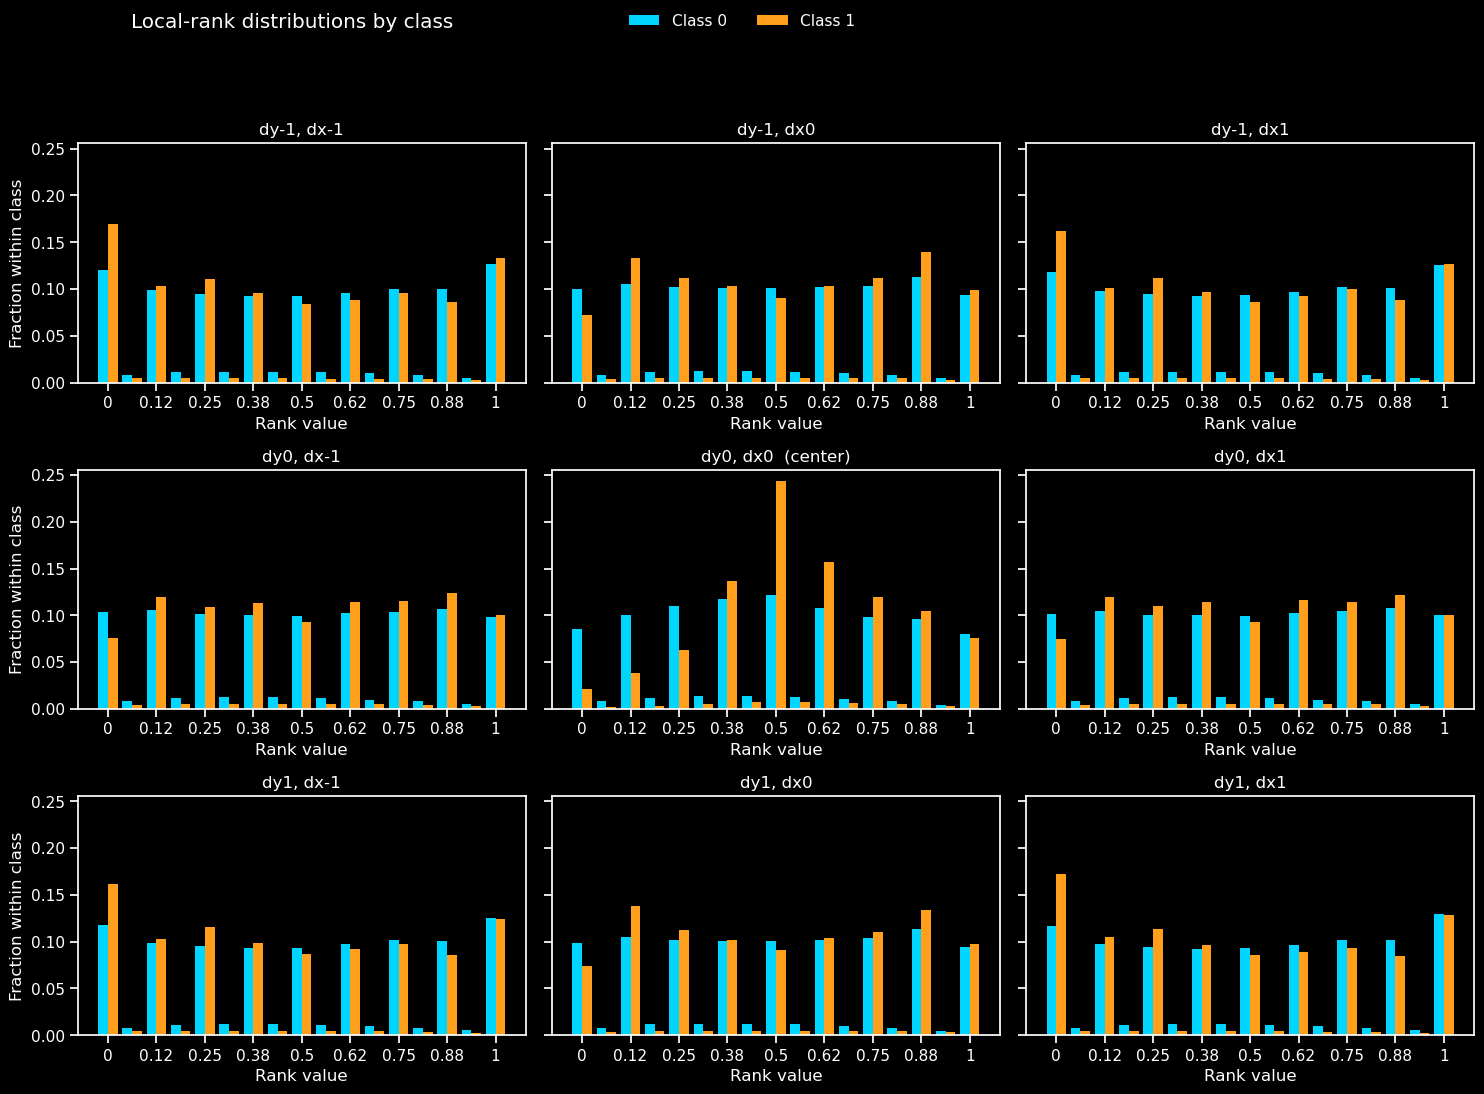

In [75]:
from matplotlib.patches import Patch

COLORS = {0: "#00d5ff", 1: "#ff9f1c"}
INTENSITY_COL = "intensity_z" if "intensity_z" in df.columns else "intensity"

derivative_cols = ["Ix", "Iy", "Ixx", "Iyy", "Ixy"]
rank_cols = ["win_dy-1_dx-1", "win_dy-1_dx0", "win_dy-1_dx1",
             "win_dy0_dx-1",  "win_dy0_dx0",  "win_dy0_dx1",
             "win_dy1_dx-1",  "win_dy1_dx0",  "win_dy1_dx1"]

# Subsample (stratified by fish) for the slow plots; rank bars use the full df
fish_key = df["file"].astype(str).str.split("_").str[0]
samp = (df.assign(_fish=fish_key)
          .groupby("_fish", group_keys=False)
          .apply(lambda g: g.sample(min(len(g), 50_000), random_state=0)))

class_legend = [Patch(facecolor=COLORS[c], label=f"Class {c}") for c in (0, 1)]

# ---------- 1. Intensity: density by class ----------
fig, ax = plt.subplots(figsize=(8, 5))
hi = samp[INTENSITY_COL].quantile(0.995)
for cls in (0, 1):
    sns.kdeplot(data=samp[samp["label"] == cls], x=INTENSITY_COL,
                color=COLORS[cls], lw=3, label=f"Class {cls}", ax=ax,
                common_norm=False, clip=(samp[INTENSITY_COL].min(), hi),
                warn_singular=False)
ax.set_title("Intensity distribution by class")
ax.set_xlabel(INTENSITY_COL)
ax.set_ylabel("Density")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

# ---------- 2. Derivatives: boxplots ----------
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()
for ax, feature in zip(axes, derivative_cols):
    sns.boxplot(data=samp, x="label", y=feature, hue="label", palette=COLORS,
                legend=False, showfliers=False, width=0.5, linewidth=2.5, ax=ax,
                medianprops={"color": "white", "linewidth": 2.5},
                whiskerprops={"color": "white", "linewidth": 1.5},
                capprops={"color": "white", "linewidth": 1.5},
                boxprops={"edgecolor": "white"})
    ax.set_title(feature)
    ax.set_xlabel("Class")
    ax.set_ylabel("Feature value")
for ax in axes[len(derivative_cols):]:
    ax.axis("off")
fig.suptitle("Derivative feature distributions by class")
plt.tight_layout(); plt.show()

# ---------- 3. Rank features: within-class proportions (3x3 = pixel neighbourhood) ----------
fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharey=True)
for ax, feature in zip(axes.ravel(), rank_cols):
    d = df[[feature, "label"]].dropna()
    d[feature] = d[feature].round(3)                      # avoid float-noise duplicate bins
    props = (pd.crosstab(d[feature], d["label"], normalize="columns")
               .reindex(columns=[0, 1], fill_value=0))
    x = np.arange(len(props))
    ax.bar(x - 0.2, props[0], width=0.4, color=COLORS[0])
    ax.bar(x + 0.2, props[1], width=0.4, color=COLORS[1])
    step = max(1, len(props) // 6)                        # thin out tick labels
    ax.set_xticks(x[::step])
    ax.set_xticklabels([f"{v:.2g}" for v in props.index[::step]])
    dy, dx = feature.replace("win_", "").split("_")
    ax.set_title(f"{dy}, {dx}" + ("  (center)" if feature == "win_dy0_dx0" else ""))
    ax.set_xlabel("Rank value")
for ax in axes[:, 0]:
    ax.set_ylabel("Fraction within class")

fig.legend(handles=class_legend, loc="upper center", ncol=2, frameon=False)
fig.suptitle("Local-rank distributions by class", y=0.99, x=0.2)
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()




constant features: none


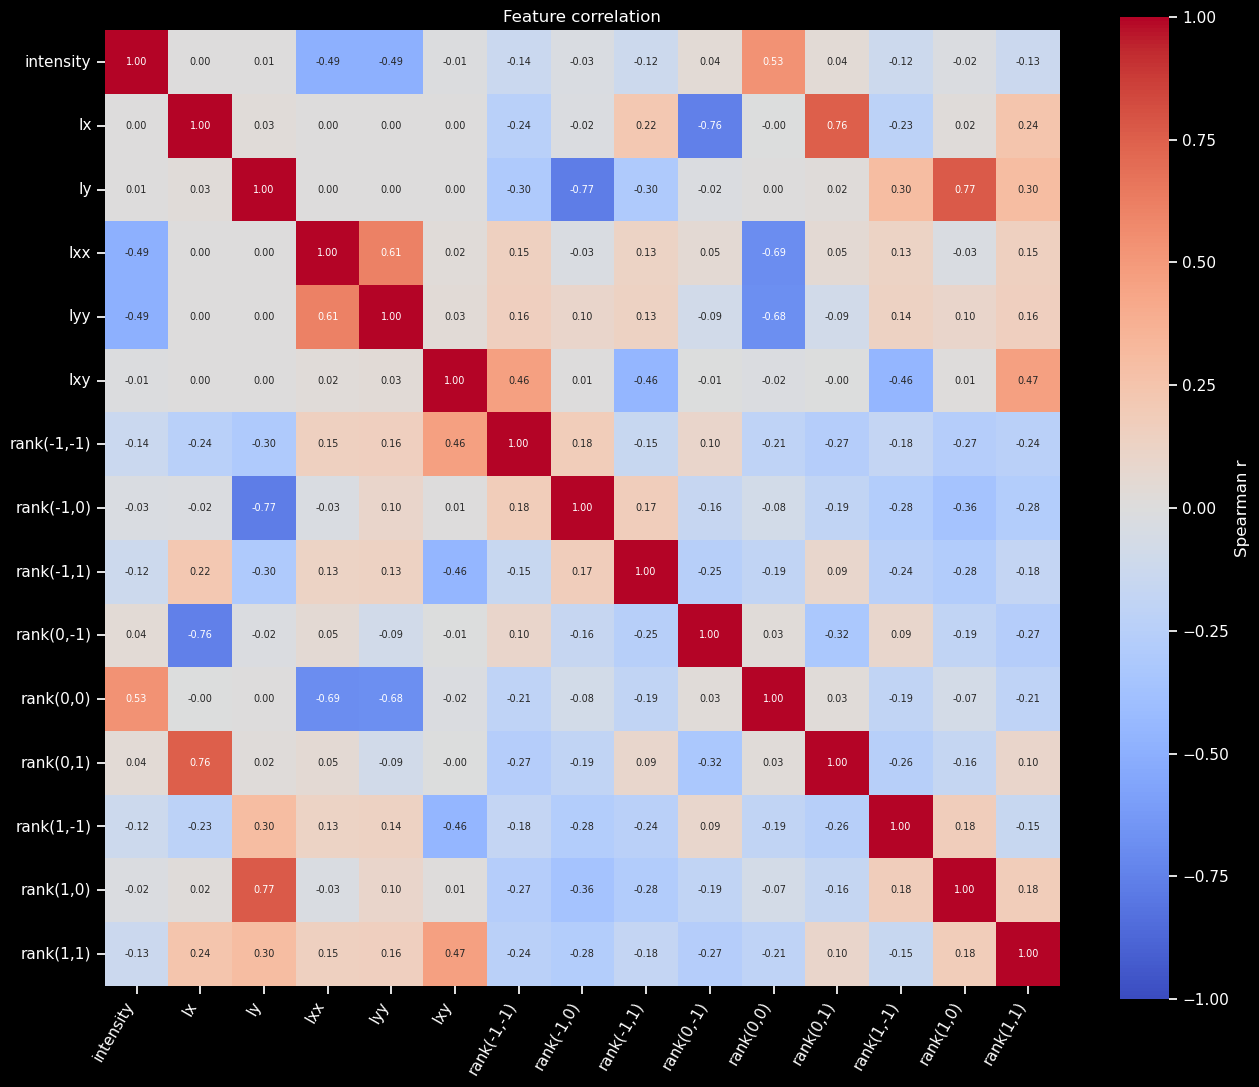

       feat_a        feat_b     r
37         Iy   win_dy1_dx0  0.77
31         Iy  win_dy-1_dx0 -0.77
23         Ix   win_dy0_dx1  0.76
21         Ix  win_dy0_dx-1 -0.76
45        Ixx   win_dy0_dx0 -0.69
55        Iyy   win_dy0_dx0 -0.68
39        Ixx           Iyy  0.61
9   intensity   win_dy0_dx0  0.53
3   intensity           Iyy -0.49
2   intensity           Ixx -0.49
       feat_a        feat_b     r
37         Iy   win_dy1_dx0  0.77
31         Iy  win_dy-1_dx0 -0.77
23         Ix   win_dy0_dx1  0.76
21         Ix  win_dy0_dx-1 -0.76
45        Ixx   win_dy0_dx0 -0.69
55        Iyy   win_dy0_dx0 -0.68
39        Ixx           Iyy  0.61
9   intensity   win_dy0_dx0  0.53
3   intensity           Iyy -0.49
2   intensity           Ixx -0.49


In [81]:
FEATURE_COLS = ["intensity", "Ix", "Iy", "Ixx", "Iyy", "Ixy",
                "win_dy-1_dx-1", "win_dy-1_dx0", "win_dy-1_dx1",
                "win_dy0_dx-1",  "win_dy0_dx0",  "win_dy0_dx1",
                "win_dy1_dx-1",  "win_dy1_dx0",  "win_dy1_dx1"]
GROUP_LINES = False      # True: draw separators between intensity | derivatives | rank window
BY_CLASS = None          # None = all pixels; 0 or 1 = only that class

d = samp if BY_CLASS is None else samp[samp["label"] == BY_CLASS]

# check for constant features (these produce blank rows/columns)
const = [c for c in FEATURE_COLS if d[c].nunique() <= 1]
print("constant features:", const if const else "none")

corr = d[FEATURE_COLS].corr(method="spearman")
assert np.allclose(corr.values, corr.values.T, equal_nan=True)   # confirms symmetry

def short(c):
    if c.startswith("win_"):
        dy, dx = c[4:].split("_")
        return f"rank({dy[2:]},{dx[2:]})"
    return c
labels = [short(c) for c in corr.columns]

n = len(corr)
fig, ax = plt.subplots(figsize=(0.75 * n + 2, 0.75 * n + 1.5))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True,
            linewidths=0, xticklabels=labels, yticklabels=labels,
            cbar_kws={"label": "Spearman r", "shrink": 0.8}, ax=ax)

if GROUP_LINES:
    for b in (1, 6):
        ax.axhline(b, color="white", lw=1.5)
        ax.axvline(b, color="white", lw=1.5)

ax.set_title("Feature correlation" + ("" if BY_CLASS is None else f" (class {BY_CLASS} only)"))
plt.xticks(rotation=60, ha="right")
plt.tight_layout(); plt.show()

# most redundant pairs (upper triangle only, so each pair appears once)
iu = np.triu_indices(n, k=1)
pairs = pd.DataFrame({"feat_a": corr.index[iu[0]], "feat_b": corr.columns[iu[1]],
                      "r": corr.values[iu]})
print(pairs.reindex(pairs["r"].abs().sort_values(ascending=False).index).head(10).round(2))
print(pairs.reindex(pairs["r"].abs().sort_values(ascending=False).index).head(10).round(2))